In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("D:/DATA/aitpune/college study thingy/ml/dataset/uber.csv")
print(df.shape)
df.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
print("dataset info:")
df.info()

dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB


In [4]:
print("missing values:")
df.isnull().sum()

missing values:


Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [5]:
print("statistical summary:")
df.describe()

statistical summary:


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [7]:
df = df.drop(columns = ["Unnamed: 0", "key"], errors="ignore")

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors = "coerce",
    utc=True
)

df = df.dropna()
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5


In [8]:
df = df[
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180))
].copy()

print("shape after coordinate validation:", df.shape)

shape after coordinate validation: (199987, 7)


In [9]:
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["weekday"] = df["pickup_datetime"].dt.dayofweek

df = df.drop(columns=["pickup_datetime"])
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,weekday
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,3


In [10]:
lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])

lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])

dlat = lat2-lat1
dlon = lon2-lon1

a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2

df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,weekday,distance
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,3,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,4,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,0,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,4,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,3,4.475450


In [11]:
df = df[
    (df["fare_amount"] >=0) &
    (df["distance"]  >= 0) &
    (df["passenger_count"] >= 1)
].copy()

print("shape after validation:", df.shape)

shape after validation: (199262, 11)


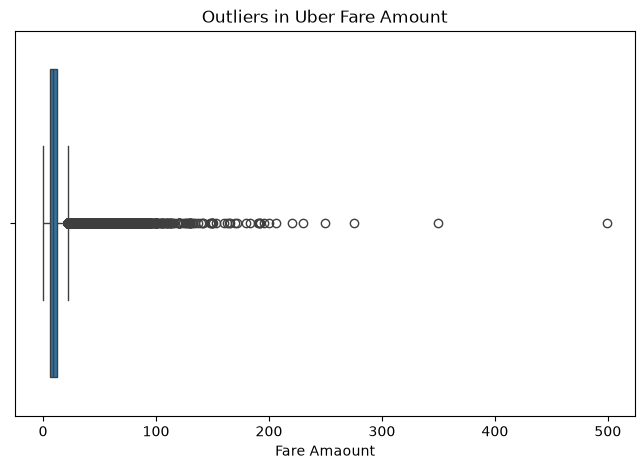

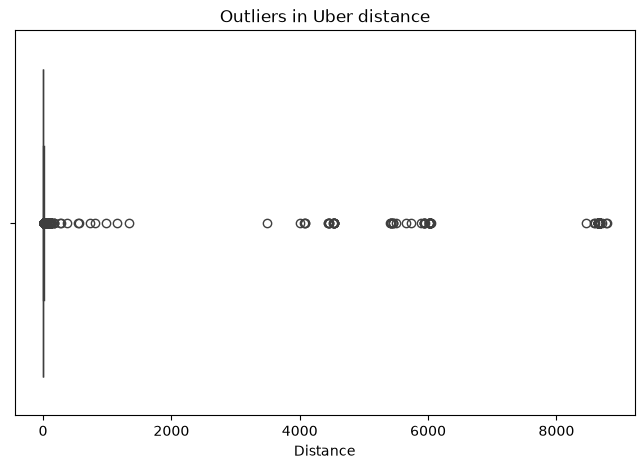

In [12]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["fare_amount"])

plt.title("Outliers in Uber Fare Amount")
plt.xlabel("Fare Amaount")

plt.figure(figsize=(8,5))
sns.boxplot(x=df["distance"])

plt.title("Outliers in Uber distance")
plt.xlabel("Distance")

plt.show()

In [13]:
q1 = df[["fare_amount", "distance"]].quantile(0.25)
q3 = df[["fare_amount", "distance"]].quantile(0.75)

iqr = q3-q1
lower = q1 - 1.5*iqr
upper = q3 + 1.5*iqr

outliers = df[
    (df["fare_amount"] < lower["fare_amount"]) |
    (df["fare_amount"] > upper["fare_amount"]) |
    (df["distance"] < lower["distance"]) |
    (df["distance"] > upper["distance"])
]

print("number of outlier rows:", len(outliers))

number of outlier rows: 20539


In [15]:
df = df[
    (df["fare_amount"] >= lower["fare_amount"]) &
    (df["fare_amount"] <= upper["fare_amount"]) &
    (df["distance"] >= lower["distance"]) &
    (df["distance"] <= upper["distance"]) 
].copy()

print("shape after removing outliers:", df.shape)

shape after removing outliers: (178723, 11)


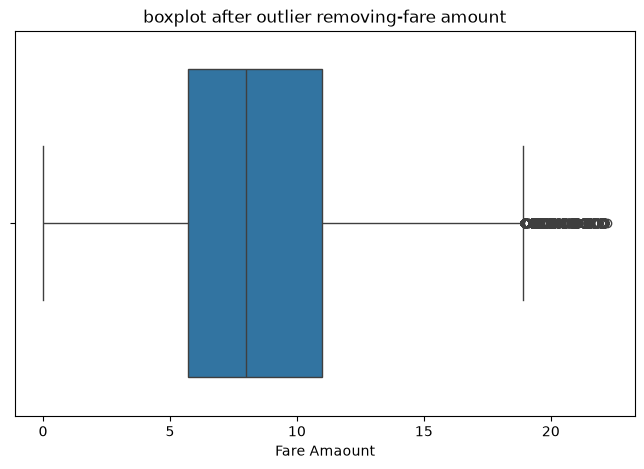

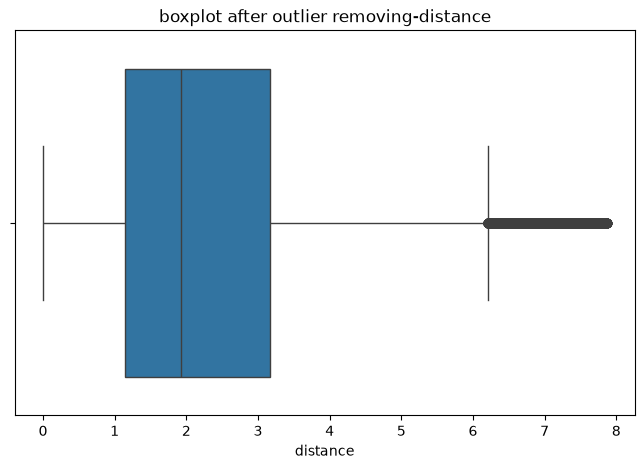

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(x = df["fare_amount"])

plt.title("boxplot after outlier removing-fare amount")
plt.xlabel("Fare Amaount")

plt.figure(figsize=(8,5))
sns.boxplot(x = df["distance"])

plt.title("boxplot after outlier removing-distance")
plt.xlabel("distance")
plt.show()

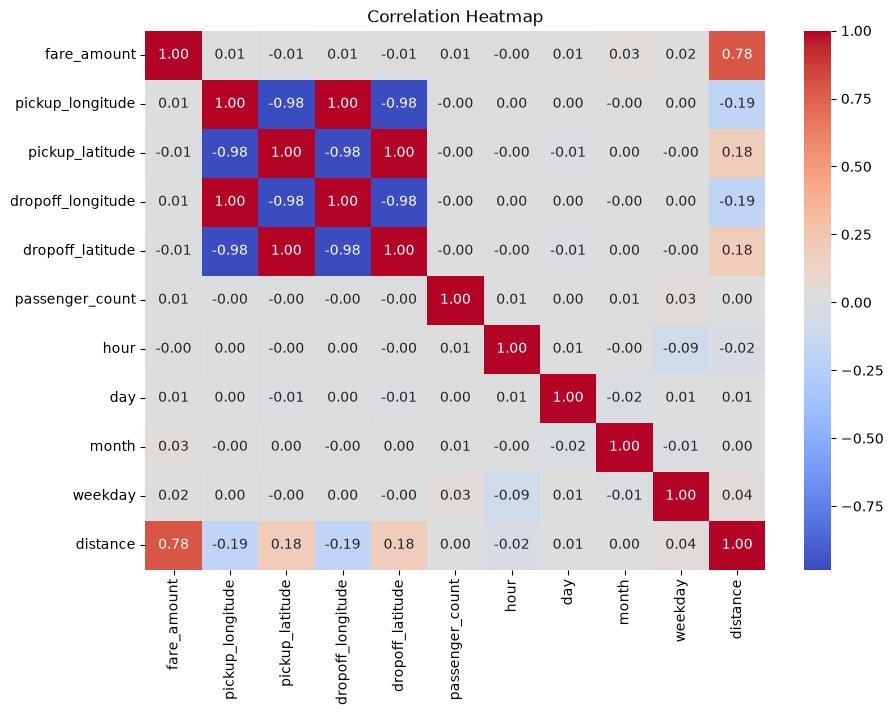

In [17]:
plt.figure(figsize=(10,7))

correlation = df.corr(numeric_only = True)
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt = ".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [18]:
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("training data:", X_train.shape)
print("Testing data:", X_test.shape)

training data: (142978, 10)
Testing data: (35745, 10)


In [19]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

print("linear regression model trained sucessfully.")

linear regression model trained sucessfully.


In [20]:
rf = RandomForestRegressor(
    n_estimators = 50,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [21]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE" :[
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
        ],
    "MSE": [
        mean_squared_error(y_test, lr_pred),
        mean_squared_error(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "R2 score" :[
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ]
})

print(results)

               Model       MAE       MSE      RMSE  R2 score
0  Linear Regression  1.701565  5.676436  2.382527  0.635947
1      Random Forest  1.527471  4.751126  2.179708  0.695291
